# 02 - Clasificación

Dos técnicas × 5 configuraciones de hiperparámetros, evaluadas con cross-validation (Tarea 2).

**Decisiones del grupo:**
- **Técnicas:** Árbol de decisión (Clase 3) y Regresión logística (Clase 7). Son modelos muy distintos entre sí (reglas vs. lineal), lo que además favorece al Stacking de la Tarea 3.
- **Cross-validation:** `StratifiedKFold` de 10 folds, con los **mismos folds** para todos los modelos.
- **`Student ID`:** target encoding **dentro de cada fold** (en un `Pipeline`), para evitar *data leakage*.
- **Métricas (Clase 4):** accuracy, precision, recall, F1 y AUC-ROC, con clase positiva 1 = respuesta correcta.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))  # para poder importar src/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import TargetEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
import sklearn
print('scikit-learn', sklearn.__version__)  # se necesita 1.8 o superior (por TargetEncoder y l1_ratio)

from src.utils import TARGET, DATOS_PROCESADOS, RAIZ

RESULTADOS = RAIZ / 'resultados'
SEMILLA = 42

scikit-learn 1.9.1


## 1. Carga de datos

Se usa el dataset generado por el notebook 01 (hay que correrlo antes).

In [2]:
df = pd.read_csv(DATOS_PROCESADOS / 'datos_procesados.csv')

X = df.drop(columns=TARGET)
y = df[TARGET]

print('X:', X.shape, '| y:', y.shape)
print(y.value_counts(normalize=True).round(3))

X: (9546, 239) | y: (9546,)
Type of Answer
0    0.532
1    0.468
Name: proportion, dtype: float64


## 2. Esquema de evaluación

- **Folds:** `StratifiedKFold` con 10 folds y semilla fija. Así todos los modelos (y el Stacking del notebook 03) se evalúan sobre exactamente las mismas particiones.
- **Pipeline:** `TargetEncoder` sobre `Student ID` → modelo. Como el encoder está dentro del pipeline, en cada fold el historial de cada estudiante se calcula **solo con los datos de train**. Los estudiantes que no están en train reciben el promedio general. El resto de las columnas (ya numéricas) pasa sin cambios.
- No se escalan las variables: todas quedan entre 0 y 1 (binarias, o la tasa de acierto del target encoding).
- **No se reporta el accuracy en train.** Dentro del train, `TargetEncoder` calcula el historial con un CV interno (*cross-fitting*) para que el modelo no se entrene con información de la propia respuesta. Al predecir sobre ese mismo train, en cambio, usa el historial completo. Como el modelo ve valores distintos al entrenar y al predecir, el accuracy en train no mide la memorización real y no sirve para detectar overfitting. El overfitting se detecta comparando las métricas de test a medida que aumenta la complejidad del modelo.

In [3]:
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)

METRICAS = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']


def crear_pipeline(modelo):
    """Target encoding de Student ID (dentro de cada fold) + modelo."""
    encoder = ColumnTransformer(
        [('te_student', TargetEncoder(target_type='binary',
                                      cv=StratifiedKFold(5, shuffle=True, random_state=SEMILLA)),
          ['Student ID'])],
        remainder='passthrough',
    )
    return make_pipeline(encoder, modelo)


def evaluar(nombre, modelo, X, y):
    """Evalúa un modelo con cross-validation y devuelve el promedio y el desvío de cada métrica."""
    res = cross_validate(crear_pipeline(modelo), X, y, cv=cv, scoring=METRICAS)
    fila = {'modelo': nombre}
    for m in METRICAS:
        fila[m] = res[f'test_{m}'].mean()
        fila[f'{m}_std'] = res[f'test_{m}'].std()
    return fila


def ic95(valores):
    """Media e intervalo de confianza del 95 % (distribución t de Student)."""
    valores = np.asarray(valores)
    n = len(valores)
    media = valores.mean()
    margen = stats.t.ppf(0.975, n - 1) * valores.std(ddof=1) / np.sqrt(n)
    return media, media - margen, media + margen

## 3. Selección de características: ¿aportan las keywords?

En el EDA vimos que las 191 keywords generan columnas muy dispersas y que la mayoría pertenece a un único subtopic. Antes de entrenar los 10 modelos, se comparan tres conjuntos de columnas usando una configuración intermedia de cada técnica:

| Conjunto | Columnas |
|---|---|
| A. Sin keywords | Student ID, Level, Country, Topic, Subtopic |
| B. Top 30 keywords | A + las 30 keywords más frecuentes |
| C. Todas las keywords | A + las 191 keywords |

In [4]:
cols_kw = [c for c in X.columns if c.startswith('KW_')]
cols_sin_kw = [c for c in X.columns if not c.startswith('KW_')]
top30_kw = X[cols_kw].sum().sort_values(ascending=False).head(30).index.tolist()

conjuntos = {
    'A. Sin keywords': cols_sin_kw,
    'B. Top 30 keywords': cols_sin_kw + top30_kw,
    'C. Todas las keywords': cols_sin_kw + cols_kw,
}

modelos_base = {
    'Árbol (max_depth=8)': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'Reg. logística (C=1)': LogisticRegression(C=1, max_iter=2000),
}

filas = []
for nombre_conj, cols in conjuntos.items():
    for nombre_mod, modelo in modelos_base.items():
        fila = evaluar(nombre_mod, modelo, X[cols], y)
        fila['conjunto'] = nombre_conj
        fila['n_columnas'] = len(cols)
        filas.append(fila)

sel = pd.DataFrame(filas)
display(sel.pivot_table(index=['conjunto', 'n_columnas'], columns='modelo',
                        values=['accuracy', 'f1', 'roc_auc']).round(3))

accuracy                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       48                        0.650               0.646   
B. Top 30 keywords    78                        0.656               0.645   
C. Todas las keywords 239                       0.659               0.647   

                                                   f1                      \
modelo                           Reg. logística (C=1) Árbol (max_depth=8)   
conjunto              n_columnas                                            
A. Sin keywords       48                        0.622               0.640   
B. Top 30 keywords    78                        0.629               0.637   
C. Todas las keywords 239                       0.631               0.620   

                                              roc_auc                      
modelo                           Reg. logística (C=1) Árbol (max_depth=8)  
conjunto              n_columnas                                           
A. Sin keywords       48                        0.705               0.696  
B. Top 30 keywords    78                        0.705               0.695  
C. Todas las keywords 239                       0.705               0.698

**Conclusión:** las keywords casi no aportan información. Pasar de 48 columnas (sin keywords) a 239 (todas) mejora el accuracy de la regresión logística de 0,650 a 0,659 y deja al árbol prácticamente igual (de 0,646 a 0,647). El AUC no cambia: se mantiene en 0,705 para la logística y entre 0,695 y 0,698 para el árbol. Esto es coherente con lo observado en el EDA: la mayoría de las keywords pertenece a un único subtopic, por lo que su información ya está contenida en la variable `Subtopic`.

Ante un rendimiento equivalente, elegimos el **conjunto A (sin keywords, 48 columnas)**, ya que es el modelo más simple: entrena más rápido, es más fácil de interpretar y reduce el riesgo de sobreajuste por tener muchas columnas dispersas.

In [5]:
# Conjunto de columnas elegido para el resto del TP (cambiar si el grupo decide otro)
COLUMNAS = conjuntos['A. Sin keywords']
X_sel = X[COLUMNAS]
print('Columnas usadas:', X_sel.shape[1])

Columnas usadas: 48


## 4. Técnica 1: Árbol de decisión

Se varían la profundidad, el mínimo de muestras por hoja y el criterio de división, de un árbol muy simple (riesgo de *underfitting*) a uno sin límite (riesgo de *overfitting*).

| Config. | Hiperparámetros |
|---|---|
| T1 | `max_depth=3` |
| T2 | `max_depth=5` |
| T3 | `max_depth=8`, `min_samples_leaf=20` |
| T4 | `max_depth=12`, `min_samples_leaf=10`, `criterion='entropy'` |
| T5 | `max_depth=None` (sin límite) |

In [6]:
arboles = {
    'T1 max_depth=3': DecisionTreeClassifier(max_depth=3, random_state=SEMILLA),
    'T2 max_depth=5': DecisionTreeClassifier(max_depth=5, random_state=SEMILLA),
    'T3 max_depth=8, leaf=20': DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, random_state=SEMILLA),
    'T4 max_depth=12, leaf=10, entropy': DecisionTreeClassifier(max_depth=12, min_samples_leaf=10,
                                                                criterion='entropy', random_state=SEMILLA),
    'T5 sin límite': DecisionTreeClassifier(max_depth=None, random_state=SEMILLA),
}

res_arbol = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in arboles.items()]).set_index('modelo')
display(res_arbol[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
T1 max_depth=3,0.652,0.629,0.631,0.629,0.699
T2 max_depth=5,0.649,0.627,0.622,0.623,0.700
"T3 max_depth=8, leaf=20",0.646,0.612,0.673,0.640,0.696
"T4 max_depth=12, leaf=10, entropy",0.639,0.613,0.624,0.618,0.686
T5 sin límite,0.612,0.591,0.557,0.573,0.616


## 5. Técnica 2: Regresión logística

Se varía la regularización `C` (menor `C` = más regularización = modelo más simple) y el tipo de penalización.

| Config. | Hiperparámetros |
|---|---|
| L1 | `C=0.01` |
| L2 | `C=0.1` |
| L3 | `C=1` (valor por defecto) |
| L4 | `C=10` |
| L5 | `C=1`, penalización L1 (Lasso) |

In [7]:
logisticas = {
    'L1 C=0.01': LogisticRegression(C=0.01, max_iter=2000),
    'L2 C=0.1': LogisticRegression(C=0.1, max_iter=2000),
    'L3 C=1': LogisticRegression(C=1, max_iter=2000),
    'L4 C=10': LogisticRegression(C=10, max_iter=2000),
    'L5 C=1, L1': LogisticRegression(C=1, l1_ratio=1, solver='liblinear', max_iter=2000),
}

res_log = pd.DataFrame([evaluar(n, m, X_sel, y) for n, m in logisticas.items()]).set_index('modelo')
display(res_log[METRICAS].round(3))

,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
L1 C=0.01,0.643,0.647,0.521,0.577,0.702
L2 C=0.1,0.652,0.634,0.605,0.619,0.705
L3 C=1,0.650,0.629,0.616,0.622,0.705
L4 C=10,0.651,0.630,0.616,0.623,0.705
"L5 C=1, L1",0.653,0.632,0.620,0.626,0.706


## 6. Promedio de las 5 ejecuciones (Tarea 2.b)

Para cada técnica se promedia cada métrica entre sus 5 configuraciones, con su intervalo de confianza del 95 %.

In [8]:
def resumen_tecnica(res):
    filas = {}
    for m in METRICAS:
        media, inf, sup = ic95(res[m])
        filas[m] = {'media': media, 'IC95 inf': inf, 'IC95 sup': sup}
    return pd.DataFrame(filas).T

promedios = pd.concat({'Árbol de decisión': resumen_tecnica(res_arbol),
                       'Regresión logística': resumen_tecnica(res_log)}, axis=1)
display(promedios.round(3))

Árbol de decisión                   Regresión logística           \
                      media IC95 inf IC95 sup               media IC95 inf   
accuracy              0.639    0.619    0.660               0.650    0.645   
precision             0.614    0.596    0.633               0.634    0.625   
recall                0.621    0.570    0.673               0.596    0.544   
f1                    0.617    0.585    0.648               0.613    0.588   
roc_auc               0.679    0.635    0.724               0.705    0.703   

                    
          IC95 sup  
accuracy     0.655  
precision    0.643  
recall       0.648  
f1           0.639  
roc_auc      0.707

## 7. Comparación de resultados (Tarea 2.c)

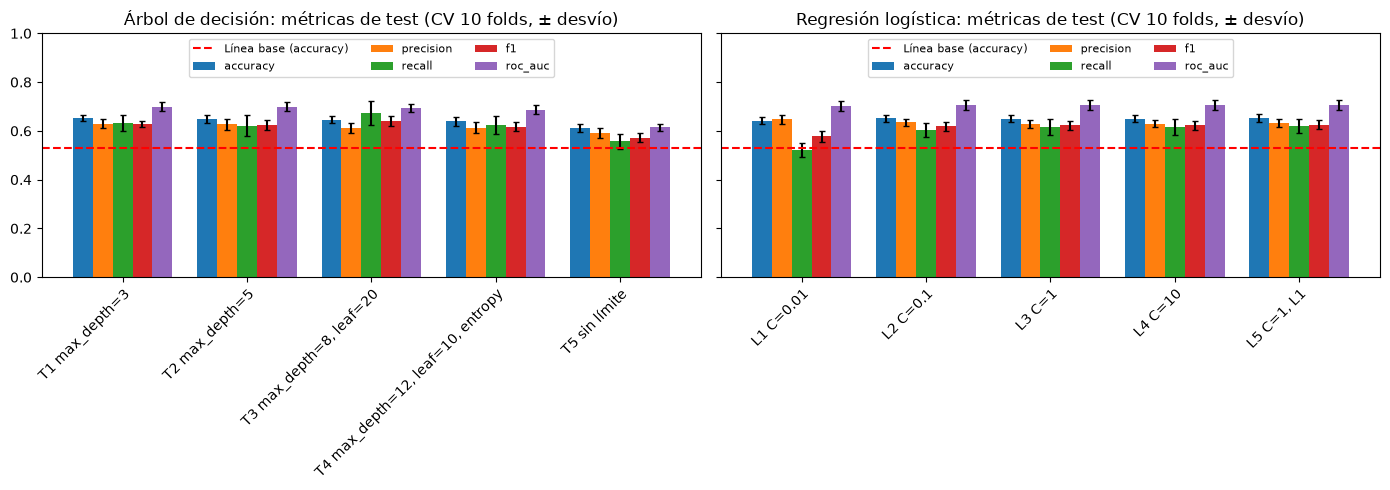

,accuracy,precision,recall,f1,roc_auc
tecnica,,,,,
Reg. logística,0.650,0.634,0.596,0.613,0.705
Árbol,0.639,0.614,0.621,0.617,0.679


In [9]:
# Métricas de cada configuración (promedio de los 10 folds)
comparacion = pd.concat([res_arbol.assign(tecnica='Árbol'), res_log.assign(tecnica='Reg. logística')])

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (tecnica, res) in zip(axes, [('Árbol de decisión', res_arbol), ('Regresión logística', res_log)]):
    res[METRICAS].plot.bar(ax=ax, width=0.8, yerr=res[[f'{m}_std' for m in METRICAS]].values.T, capsize=2)
    ax.axhline(y.value_counts(normalize=True).max(), color='red', linestyle='--', label='Línea base (accuracy)')
    ax.set_ylim(0, 1)
    ax.set_title(f'{tecnica}: métricas de test (CV 10 folds, ± desvío)')
    ax.set_xlabel('')
    plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor')
    ax.legend(loc='upper center', ncol=3, fontsize=8)
plt.tight_layout()
plt.show()

display(comparacion.groupby('tecnica')[METRICAS].mean().round(3))

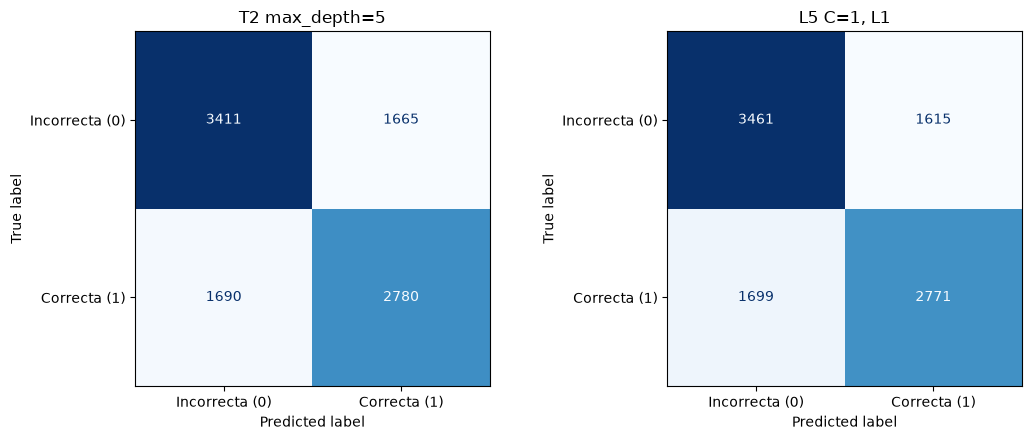

In [10]:
# Matriz de confusión de la mejor configuración de cada técnica (según AUC)
mejor_arbol = res_arbol['roc_auc'].idxmax()
mejor_log = res_log['roc_auc'].idxmax()

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, modelo) in zip(axes, [(mejor_arbol, arboles[mejor_arbol]),
                                       (mejor_log, logisticas[mejor_log])]):
    y_pred = cross_val_predict(crear_pipeline(modelo), X_sel, y, cv=cv)
    ConfusionMatrixDisplay.from_predictions(y, y_pred, display_labels=['Incorrecta (0)', 'Correcta (1)'],
                                            cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

In [11]:
# Se guardan los resultados para el notebook 03 y el informe
comparacion.to_csv(RESULTADOS / 'resultados_tarea2.csv')
promedios.to_csv(RESULTADOS / 'promedios_tarea2.csv')
sel.to_csv(RESULTADOS / 'seleccion_caracteristicas.csv', index=False)
print('Guardado en', RESULTADOS.relative_to(RAIZ))

Guardado en resultados


## 8. Conclusiones

**1. Ambas técnicas superan la línea base.** Un modelo que predijera siempre "incorrecta" acertaría el 53,2 % de los casos. Los dos modelos rondan el 65 % de accuracy y un AUC cercano a 0,70, así que aprenden un patrón real a partir de los datos. Aun así, el problema es difícil: predecir si un estudiante responderá bien una pregunta tiene un componente impredecible que las variables disponibles no capturan.

**2. Árbol de decisión: el overfitting se ve con claridad.** Las configuraciones T1 a T3 rinden de forma muy similar (accuracy entre 0,646 y 0,652, AUC entre 0,696 y 0,700), y T4 queda apenas por debajo (AUC 0,686). Que un árbol de profundidad 3 rinda igual que uno de profundidad 8 indica que el patrón de los datos es relativamente simple. En cambio, el árbol sin límite (T5) cae a 0,612 de accuracy y 0,616 de AUC: al crecer sin restricciones memoriza el ruido del entrenamiento y generaliza peor.

**3. Regresión logística: estable, con underfitting solo en el extremo.** Con `C=0,01` (L1) la regularización es tan fuerte que el modelo queda demasiado rígido y tiende a predecir "incorrecta": su recall baja a 0,521. A partir de `C=0,1` los resultados se estabilizan (accuracy entre 0,650 y 0,653, AUC entre 0,705 y 0,706), y la penalización L1 (configuración L5) rinde igual que la L2 con el mismo `C`. Al ser un modelo lineal, aflojar la regularización no la lleva a sobreajustar.

**4. Las diferencias entre las mejores configuraciones son menores que la variabilidad entre folds.** El desvío del accuracy entre los 10 folds ronda los 1,5 puntos, mientras que las mejores configuraciones de cada técnica se diferencian por décimas. Por eso, aunque según el AUC las mejores son T2 (0,700) y L5 (0,706), en la práctica empatan con T1–T3 y con L2–L4, respectivamente.

**5. Comparación entre técnicas.** Promediando las 5 configuraciones de cada una:

| Métrica | Árbol de decisión | Regresión logística |
|---|---|---|
| Accuracy | 0,639 (IC 95 %: 0,619 – 0,660) | 0,650 (IC 95 %: 0,645 – 0,655) |
| Precision | 0,614 | 0,634 |
| Recall | 0,621 | 0,596 |
| F1 | 0,617 | 0,613 |
| AUC | 0,679 (IC 95 %: 0,635 – 0,724) | 0,705 (IC 95 %: 0,703 – 0,707) |

La **regresión logística es levemente superior** en accuracy, precision y AUC, y sobre todo **mucho más estable**: sus intervalos de confianza son muy angostos porque las 5 configuraciones dan resultados casi idénticos. El árbol es más sensible a la elección de hiperparámetros, y su promedio baja por el sobreajuste de T5. El recall promedio del árbol es algo mayor, pero esa diferencia viene sobre todo de la logística con `C=0,01`, que detecta bastante menos respuestas correctas que las demás configuraciones (recall 0,521).

**6. Matriz de confusión de la mejor configuración de cada técnica (según AUC).**

| | Árbol (T2, `max_depth=5`) | Regresión logística (L5, `C=1`, penalización L1) |
|---|---|---|
| Verdaderos negativos | 3.411 | 3.461 |
| Falsos positivos | 1.665 | 1.615 |
| Falsos negativos | 1.690 | 1.699 |
| Verdaderos positivos | 2.780 | 2.771 |
| Errores totales | 3.355 | 3.314 |

Las mejores configuraciones de ambas técnicas cometen una cantidad y un tipo de errores muy parecidos: las dos detectan alrededor del 62 % de las respuestas correctas, y la logística identifica apenas mejor las incorrectas (68,2 % frente a 67,2 %), con algunos falsos positivos menos.

**7. Implicancias para el Stacking.** Dos técnicas muy distintas (una basada en reglas y otra lineal) llegan al mismo techo de rendimiento (≈ 65 %) y cometen errores similares. Esto sugiere que el límite está en la información disponible en los datos más que en el modelo elegido. En la Tarea 3 evaluaremos si combinarlas mediante Stacking logra superar ese techo; dado lo anterior, es esperable que la mejora, si la hay, sea pequeña.